<a href="https://colab.research.google.com/github/madeeha-noor/BERT-Fine-Tuning-Reproduction/blob/main/notebooks/04_SST2_Reproduction_M3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Full SST-2 fine-tuning with our own DataLoader, mixed precision, warmup + linear decay, gradient clipping and checkpoints saved on the Colab disk.

# M3: SST-2 reproduction (BERT-base)
Full SST-2 fine-tuning with our own DataLoader, mixed precision, warmup + linear decay, gradient clipping and Drive checkpoints.
Paper reports 93.5% (GLUE test). We evaluate on the 872-sentence validation set because GLUE test labels are hidden.

In [1]:
!pip -q install transformers datasets scikit-learn

import os, math, time, random
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.metrics import confusion_matrix, classification_report

CKPT_DIR = "/content/checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)

PyTorch: 2.14.1+cu130 | Device: cuda


In [2]:
raw = load_dataset("nyu-mll/glue", "sst2")
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
MAX_LEN = 128
PAD_ID = tokenizer.pad_token_id

class SentimentDataset(Dataset):
    def __init__(self, hf_split, tokenizer, text_col="sentence", label_col="label", max_length=MAX_LEN):
        texts = list(hf_split[text_col])
        self.labels = list(hf_split[label_col])
        enc = tokenizer(texts, truncation=True, max_length=max_length)
        self.input_ids = enc["input_ids"]
        self.token_type_ids = enc["token_type_ids"]
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        return {"input_ids": self.input_ids[idx],
                "token_type_ids": self.token_type_ids[idx],
                "label": self.labels[idx]}

def collate_fn(batch):
    B = len(batch)
    max_len = max(len(x["input_ids"]) for x in batch)
    input_ids      = torch.full((B, max_len), PAD_ID, dtype=torch.long)
    token_type_ids = torch.zeros((B, max_len), dtype=torch.long)
    attention_mask = torch.zeros((B, max_len), dtype=torch.long)
    for i, x in enumerate(batch):
        n = len(x["input_ids"])
        input_ids[i, :n]      = torch.tensor(x["input_ids"], dtype=torch.long)
        token_type_ids[i, :n] = torch.tensor(x["token_type_ids"], dtype=torch.long)
        attention_mask[i, :n] = 1
    labels = torch.tensor([x["label"] for x in batch], dtype=torch.long)
    return {"input_ids": input_ids, "token_type_ids": token_type_ids,
            "attention_mask": attention_mask, "labels": labels}

train_ds = SentimentDataset(raw["train"], tokenizer)       # ALL 67,349 sentences
val_ds   = SentimentDataset(raw["validation"], tokenizer)  # 872 sentences

def make_loaders(batch_size, seed=42):
    g = torch.Generator(); g.manual_seed(seed)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              collate_fn=collate_fn, generator=g)
    val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, collate_fn=collate_fn)
    return train_loader, val_loader

print("Train:", len(train_ds), "| Validation:", len(val_ds))

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

sst2/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  148kB            

... (5 outputs left out)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Train: 67349 | Validation: 872


In [3]:
set_seed(42)
tl, _ = make_loaders(32)
m = AutoModelForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=2).to(device)
b = {k: v.to(device) for k, v in next(iter(tl)).items()}

# Check 1: first loss should be close to ln(2) = 0.693 for 2 classes
m.eval()
with torch.no_grad():
    first_loss = m(**b).loss.item()
print(f"First loss: {first_loss:.4f}   (ln 2 = {math.log(2):.4f})")
assert abs(first_loss - math.log(2)) < 0.2

# Check 2: every parameter must receive a non-zero gradient
m.train()
m(**b).loss.backward()
bad = [n for n, p in m.named_parameters() if p.grad is None or p.grad.abs().sum() == 0]
print("Parameters with zero/missing gradient:", bad)
assert len(bad) == 0
print("Sanity checks passed.")
del m, b, tl
torch.cuda.empty_cache()

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


First loss: 0.6691   (ln 2 = 0.6931)
Parameters with zero/missing gradient: []
Sanity checks passed.


In [4]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    tot_loss, n, preds, labs = 0.0, 0, [], []
    for b in loader:
        b = {k: v.to(device) for k, v in b.items()}
        with torch.autocast("cuda", dtype=torch.float16):
            out = model(**b)
        tot_loss += out.loss.item() * b["labels"].size(0)
        n += b["labels"].size(0)
        preds.append(out.logits.argmax(-1).cpu()); labs.append(b["labels"].cpu())
    preds, labs = torch.cat(preds), torch.cat(labs)
    return tot_loss / n, (preds == labs).float().mean().item(), preds, labs


def run_experiment(lr=2e-5, batch_size=32, epochs=3, seed=42, warmup_frac=0.1):
    tag = f"lr{lr}_bs{batch_size}_ep{epochs}_seed{seed}"
    ckpt_path = f"{CKPT_DIR}/{tag}.pt"
    set_seed(seed)
    train_loader, val_loader = make_loaders(batch_size, seed)

    model = AutoModelForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=2).to(device)
    no_decay = ["bias", "LayerNorm.weight"]
    groups = [
        {"params": [p for n, p in model.named_parameters() if not any(k in n for k in no_decay)], "weight_decay": 0.01},
        {"params": [p for n, p in model.named_parameters() if any(k in n for k in no_decay)],     "weight_decay": 0.0},
    ]
    optimizer = torch.optim.AdamW(groups, lr=lr)
    total_steps = len(train_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, int(warmup_frac * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda")

    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    start_epoch = 0
    if os.path.exists(ckpt_path):                      # resume if the session is still alive
        ck = torch.load(ckpt_path, map_location=device)
        model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
        scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
        history, start_epoch = ck["history"], ck["epoch"]
        print(f"Resumed {tag} from epoch {start_epoch}")

    for epoch in range(start_epoch, epochs):
        model.train(); t0 = time.time(); tot, n = 0.0, 0
        for b in train_loader:
            b = {k: v.to(device) for k, v in b.items()}
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(**b)
            scaler.scale(out.loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            tot += out.loss.item() * b["labels"].size(0); n += b["labels"].size(0)

        val_loss, val_acc, _, _ = evaluate(model, val_loader)
        history["train_loss"].append(tot / n); history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
        print(f"[{tag}] epoch {epoch+1}/{epochs}  train_loss={tot/n:.4f}  val_loss={val_loss:.4f}  "
              f"val_acc={val_acc:.4f}  ({time.time()-t0:.0f}s)")
        torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                    "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                    "history": history, "epoch": epoch + 1}, ckpt_path)

    _, final_acc, preds, labs = evaluate(model, val_loader)
    del model, optimizer
    torch.cuda.empty_cache()
    return {"tag": tag, "history": history, "final_acc": final_acc, "preds": preds, "labels": labs}

## Training run
Baseline configuration from the paper's grid: lr 2e-5, batch 32, 3 epochs, seed 42.
Mixed precision, 10% warmup then linear decay, gradient clipping 1.0, AdamW (weight decay 0.01).
The reported number is the **last epoch** (no best-epoch picking on the validation set).

In [5]:
result = run_experiment(lr=2e-5, batch_size=32, epochs=3, seed=42)
print("\nFinal validation accuracy:", round(result["final_acc"] * 100, 2), "%")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[lr2e-05_bs32_ep3_seed42] epoch 1/3  train_loss=0.2540  val_loss=0.2169  val_acc=0.9174  (228s)
[lr2e-05_bs32_ep3_seed42] epoch 2/3  train_loss=0.1146  val_loss=0.2628  val_acc=0.9243  (210s)
[lr2e-05_bs32_ep3_seed42] epoch 3/3  train_loss=0.0702  val_loss=0.3021  val_acc=0.9312  (210s)

Final validation accuracy: 93.12 %


## Result and gap analysis
| | Accuracy |
|---|---|
| Paper (BERT-base, GLUE test) | 93.5% |
| Ours (BERT-base, SST-2 validation, lr 2e-5, batch 32, 3 epochs) | 93.12% |

**Gap:** 0.38 percentage points, which is 3 to 4 sentences out of the 872 validation sentences (one sentence = 0.11 points).
Likely reasons:
1. The paper reports the hidden GLUE **test** set; we use the **validation** set, so the two numbers are not computed on the same data.
2. The validation set is small, and we ran a single seed; fine-tuning results typically vary by a few tenths of a point between seeds.
3. Small differences in training details (warmup, weight decay, mixed precision, gradient clipping).

The baseline (lr 2e-5, batch 32, 3 epochs) was fixed before training, and the reported number is the last epoch.
Extra grid runs (same seed): lr 3e-5 gives 92.43%, lr 5e-5 gives 92.66%, batch 16 gives 92.66%.
Validation loss rises from epoch 1 to 3 while accuracy improves, which indicates growing overconfidence rather than worse predictions.

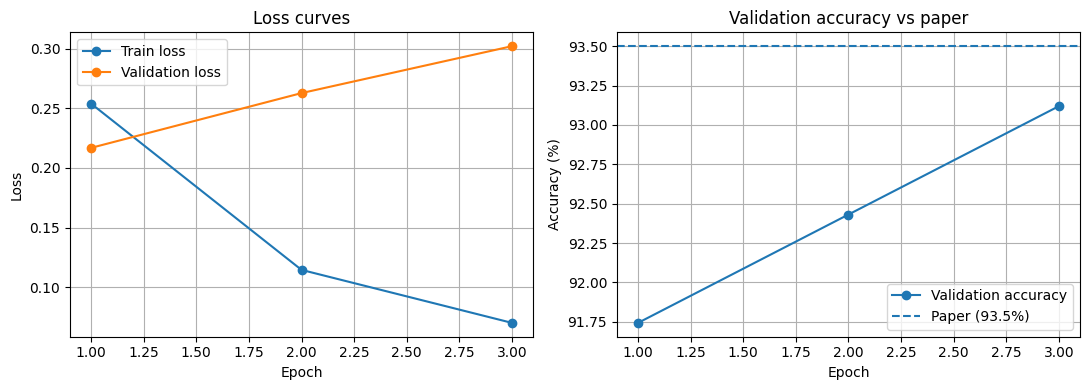

In [6]:
h = result["history"]
epochs_x = range(1, len(h["train_loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(epochs_x, h["train_loss"], marker="o", label="Train loss")
ax[0].plot(epochs_x, h["val_loss"], marker="o", label="Validation loss")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].set_title("Loss curves"); ax[0].legend(); ax[0].grid(True)

ax[1].plot(epochs_x, [a * 100 for a in h["val_acc"]], marker="o", label="Validation accuracy")
ax[1].axhline(93.5, linestyle="--", label="Paper (93.5%)")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy (%)"); ax[1].set_title("Validation accuracy vs paper")
ax[1].legend(); ax[1].grid(True)

plt.tight_layout()
plt.show()

                       Accuracy (%)
---------------------------------------------
Paper (GLUE test)             93.50
Ours (SST-2 dev)              93.12
Gap                            0.38

               precision    recall  f1-score   support

    Negative     0.9488    0.9089    0.9284       428
    Positive     0.9156    0.9527    0.9338       444

    accuracy                         0.9312       872
   macro avg     0.9322    0.9308    0.9311       872
weighted avg     0.9319    0.9312    0.9311       872



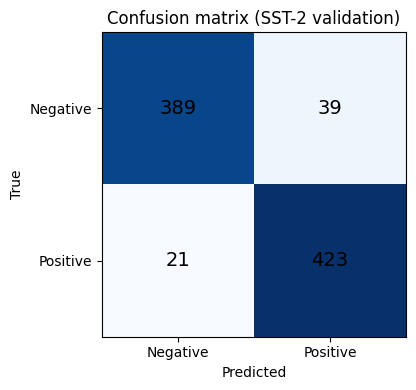

In [7]:
PAPER_ACC = 93.5
ours = result["final_acc"] * 100

print("=" * 45)
print(f"{'':20s}{'Accuracy (%)':>15s}")
print("-" * 45)
print(f"{'Paper (GLUE test)':20s}{PAPER_ACC:>15.2f}")
print(f"{'Ours (SST-2 dev)':20s}{ours:>15.2f}")
print(f"{'Gap':20s}{PAPER_ACC - ours:>15.2f}")
print("=" * 45)

preds, labs = result["preds"].numpy(), result["labels"].numpy()
print("\n", classification_report(labs, preds, target_names=["Negative", "Positive"], digits=4))

cm = confusion_matrix(labs, preds)
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Negative", "Positive"]); ax.set_yticklabels(["Negative", "Positive"])
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix (SST-2 validation)")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="black", fontsize=14)
plt.tight_layout()
plt.show()

In [8]:
import json
from google.colab import files

summary = {"tag": result["tag"], "final_val_acc": result["final_acc"], "history": result["history"]}
with open("m3_results.json", "w") as f:
    json.dump(summary, f, indent=2)
files.download("m3_results.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
grid = [
    dict(lr=3e-5, batch_size=32, epochs=3),
    dict(lr=5e-5, batch_size=32, epochs=3),
    dict(lr=2e-5, batch_size=16, epochs=3),
]

all_results = [result]
for cfg in grid:
    all_results.append(run_experiment(**cfg, seed=42))

print(f"\n{'config':38s}{'val acc (%)':>12s}")
print("-" * 50)
for r in all_results:
    print(f"{r['tag']:38s}{r['final_acc']*100:>12.2f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Resumed lr3e-05_bs32_ep3_seed42 from epoch 3


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Resumed lr5e-05_bs32_ep3_seed42 from epoch 3


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[lr2e-05_bs16_ep3_seed42] epoch 1/3  train_loss=0.2571  val_loss=0.2504  val_acc=0.9209  (383s)
[lr2e-05_bs16_ep3_seed42] epoch 2/3  train_loss=0.1325  val_loss=0.2959  val_acc=0.9266  (363s)
[lr2e-05_bs16_ep3_seed42] epoch 3/3  train_loss=0.0813  val_loss=0.3177  val_acc=0.9266  (365s)

config                                 val acc (%)
--------------------------------------------------
lr2e-05_bs32_ep3_seed42                      93.12
lr3e-05_bs32_ep3_seed42                      92.43
lr5e-05_bs32_ep3_seed42                      92.66
lr2e-05_bs16_ep3_seed42                      92.66
